# Domain-Specific Question Answering (HealthCare Issues Analyzer)

## Step1: Data Preparation and Exploratory Analysis

**Project:** Healthcare QA Assistant (English), built on MedQuAD (NIH question-answer pairs)

**Goal:** load, clean and split the data by answer, and explore healthcare related questions and answers.

**Input:** Hugging Face `keivalya/MedQuad-MedicalQnADataset`.

**Output** (in `/kaggle/working/healthcare-qa-assistant`): `data/processed/train|val|test.csv`, `results/plots/*.png`, `results/metrics/*.csv`

**Prepared by:** Alain Ishimwe Ngabo

**Facilitator:** Kevin Sebineza

## 1. Setup
Imports the libraries, sets the project folder `ROOT` and creates the output folders.

In [1]:
import os, hashlib
import numpy as np
import pandas as pd
import datasets
import matplotlib.pyplot as plt
from glob import glob
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# project root (writable folder on Kaggle)
ROOT = Path("/kaggle/working/healthcare-qa-assistant")
for folder in ["data/raw", "data/processed", "results/plots", "results/metrics"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print(ROOT)

# Huggingface setup
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret found, continuing without it")
datasets.disable_progress_bars()

/kaggle/working/healthcare-qa-assistant


## 2. Load the data
Loads MedQuAD from Hugging Face. If that fails, it reads an uploaded `medquad_raw.csv`. Columns are renamed to `question` and `answer`.

In [2]:
try:
    from datasets import load_dataset
    ds = load_dataset("keivalya/MedQuad-MedicalQnADataset", split="train")
    df = ds.to_pandas()
    print("Loaded from Hugging Face")
except Exception as e:
    print("Hugging Face not reachable:", type(e).__name__)
    matches = glob("/kaggle/input/**/medquad_raw.csv", recursive=True)
    print(matches)
    df = pd.read_csv(matches[0])
    print("Loaded from uploaded CSV")

df = df.rename(columns={"Question": "question", "Answer": "answer"})
df.to_csv(ROOT / "data/raw/medquad_raw.csv", index=False)
print(df.shape)
print(df.columns.tolist())
df.head()

Loaded from Hugging Face
(16407, 3)
['qtype', 'question', 'answer']


,qtype,question,answer
0,susceptibility,Who is at risk for Lymphocytic Choriomeningiti...,LCMV infections can occur after exposure to fr...
1,symptoms,What are the symptoms of Lymphocytic Choriomen...,LCMV is most commonly recognized as causing ne...
2,susceptibility,Who is at risk for Lymphocytic Choriomeningiti...,Individuals of all ages who come into contact ...
3,exams and tests,How to diagnose Lymphocytic Choriomeningitis (...,"During the first phase of the disease, the mos..."
4,treatment,What are the treatments for Lymphocytic Chorio...,"Aseptic meningitis, encephalitis, or meningoen..."


## 3. Raw data quality check
Here we count missing values, empty text and duplicates before anything is changed.

In [3]:
raw = df.copy()

print("Shape:", raw.shape)
print("\nColumn types:\n", raw.dtypes)
print("\nMissing values:\n", raw.isna().sum())

print("\nEmpty strings:", {
    c: int((raw[c].astype(str).str.strip() == "").sum())
    for c in ["question", "answer"]
})

print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate questions:", raw["question"].duplicated().sum())
print("Duplicate answers:", raw["answer"].duplicated().sum())
print("Unique answers:", raw["answer"].nunique())

Shape: (16407, 3)

Column types:
 qtype       object
question    object
answer      object
dtype: object

Missing values:
 qtype       0
question    0
answer      0
dtype: int64

Empty strings: {'question': 0, 'answer': 0}
Duplicate rows: 48
Duplicate questions: 1428
Duplicate answers: 590
Unique answers: 15817


## 4. Cleaning
This block removes missing rows, normalizes whitespace, drops answers under 10 words, drops duplicate pairs, and drops boilerplate answers.

In [4]:
log = [("raw", len(df))]

# Drop rows with missing question/answer
df = df.dropna(subset=["question", "answer"]).copy()
log.append(("drop missing", len(df)))

# Normalize whitespace and qtype
for col in ["question", "answer"]:
    df[col] = df[col].str.replace(r"\s+", " ", regex=True).str.strip()
df["qtype"] = df["qtype"].str.lower().str.strip()

# Drop answers shorter than 10 words
df = df[df["answer"].str.split().str.len() >= 10].copy()
log.append(("drop answers < 10 words", len(df)))

# Drop duplicate question+answer pairs
df = df.drop_duplicates(subset=["question", "answer"])
log.append(("drop duplicates", len(df)))

# Drop boilerplate answers shared by many different questions
answer_counts = df["answer"].map(df["answer"].value_counts())
boilerplate = df.loc[answer_counts > 5, "answer"]
print("Boilerplate answers:", boilerplate.nunique(), "| rows affected:", len(boilerplate))
for text, n in boilerplate.value_counts().head(3).items():
    print(f"  {n} questions -> {text[:150]}")
df = df[answer_counts <= 5].copy()
log.append(("drop boilerplate answers (>5 questions)", len(df)))

df = df.reset_index(drop=True)

# Cleaning log
cleaning_log = pd.DataFrame(log, columns=["step", "rows"])
cleaning_log["removed"] = -cleaning_log["rows"].diff().fillna(0).astype(int)
cleaning_log.to_csv(ROOT / "results/metrics/cleaning_log.csv", index=False)
cleaning_log

Boilerplate answers: 10 | rows affected: 494
  348 questions -> This condition is inherited in an autosomal recessive pattern, which means both copies of the gene in each cell have mutations. The parents of an indi
  70 questions -> This condition is inherited in an autosomal dominant pattern, which means one copy of the altered gene in each cell is sufficient to cause the disorde
  25 questions -> New types of treatment are being tested in clinical trials. Information about clinical trials is available from the NCI website. Patients may want to 


,step,rows,removed
0,raw,16407,0
1,drop missing,16407,0
2,drop answers < 10 words,16328,79
3,drop duplicates,16280,48
4,drop boilerplate answers (>5 questions),15786,494


## 5. Train / validation / test split
**What it does:** splits into 80% / 10% / 10% and make sure no overlaps.

In [5]:
# Group split
df["group"] = df["answer"].apply(lambda a: hashlib.md5(a.encode()).hexdigest())

# 80% train, 20% temp
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df["group"]))
train, temp = df.iloc[train_idx], df.iloc[temp_idx]

# split temp into 10% val, 10% test
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp, groups=temp["group"]))
val, test = temp.iloc[val_idx], temp.iloc[test_idx]

# no answer may appear in two splits
assert set(train.group).isdisjoint(val.group)
assert set(train.group).isdisjoint(test.group)
assert set(val.group).isdisjoint(test.group)

print(len(train), len(val), len(test))

12624 1585 1577


## 6. Save the splits
writes `train.csv`, `val.csv` and `test.csv` to `data/processed`.

In [6]:
processed_dir = ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

for name, part in [("train", train), ("val", val), ("test", test)]:
    out_path = processed_dir / f"{name}.csv"
    part.drop(columns="group").to_csv(out_path, index=False)

print("Splits saved to:", processed_dir)

Splits saved to: /kaggle/working/healthcare-qa-assistant/data/processed


## 7. Exploratory data analysis
Each plot below is also saved in `results/plots/` for the report.

### 7.1 Question types
counts questions per type and plots them.

qtype
information        4500
symptoms           2746
treatment          2426
genetic changes    1087
frequency          1071
inheritance         995
causes              704
exams and tests     649
research            370
outlook             359
susceptibility      322
considerations      228
prevention          205
stages               77
complications        46
support groups        1
Name: count, dtype: int64


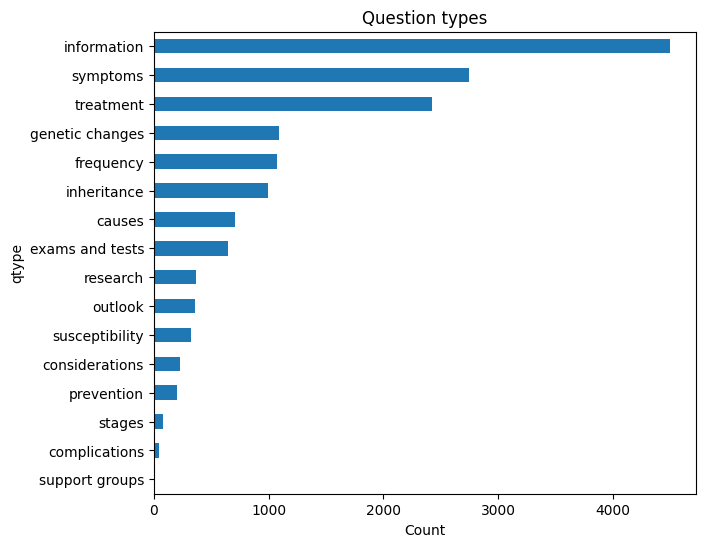

In [7]:
qtype_counts = df["qtype"].value_counts()
print(qtype_counts)

qtype_counts.sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Question types")
plt.xlabel("Count")
plt.savefig(f"{ROOT}/results/plots/question_types.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.2 Length statistics
word counts and histograms for questions and answers.

       q_words  a_words
count  15786.0  15786.0
mean       8.3    205.5
std        2.4    249.4
min        3.0     10.0
50%        8.0    143.0
90%       11.0    384.0
95%       12.0    524.0
99%       15.0   1288.1
max       27.0   4281.0


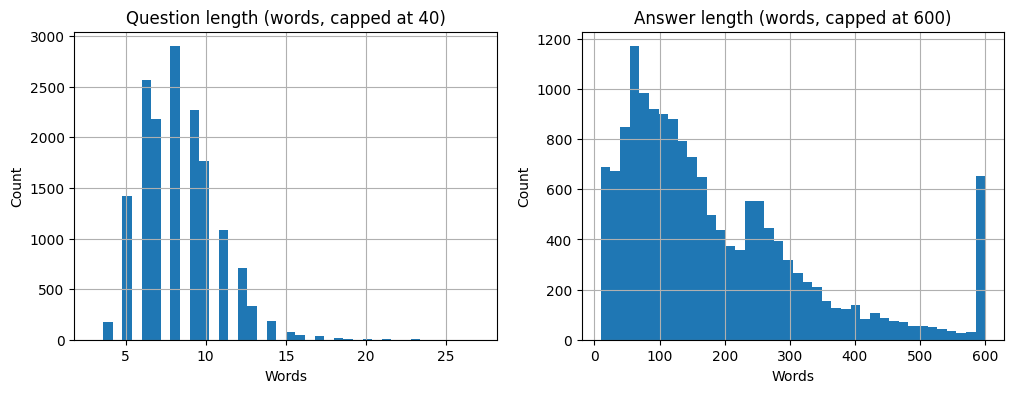

In [8]:
df["q_words"] = df["question"].str.split().str.len()
df["a_words"] = df["answer"].str.split().str.len()

print(df[["q_words", "a_words"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["q_words"].clip(upper=40).hist(bins=40, ax=axes[0])
axes[0].set(title="Question length (words, capped at 40)", xlabel="Words", ylabel="Count")
df["a_words"].clip(upper=600).hist(bins=40, ax=axes[1])
axes[1].set(title="Answer length (words, capped at 600)", xlabel="Words", ylabel="Count")
plt.savefig(f"{ROOT}/results/plots/length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.3 Truncation check
counts how many answers are longer than each model's maximum input length (needs Internet).

In [9]:
from transformers import AutoTokenizer

tok_models = {
    "MiniLM-L6": ("sentence-transformers/all-MiniLM-L6-v2", 256),
    "BGE-base": ("BAAI/bge-base-en-v1.5", 512),
    "PubMedBERT": ("NeuML/pubmedbert-base-embeddings", 512),
}

sample = df["answer"].sample(min(2000, len(df)), random_state=42).tolist()
rows = []
for name, (model_id, limit) in tok_models.items():
    tok = AutoTokenizer.from_pretrained(model_id)
    lengths = np.array([len(ids) for ids in tok(sample)["input_ids"]])
    rows.append({
        "model": name,
        "assumed_limit": limit,
        "median_tokens": int(np.median(lengths)),
        "p95_tokens": int(np.percentile(lengths, 95)),
        "pct_truncated": round(100 * (lengths > limit).mean(), 1),
    })

truncation = pd.DataFrame(rows)
truncation.to_csv(ROOT / "results/metrics/truncation.csv", index=False)
truncation

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (826 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (826 > 512). Running this sequence through the model will result in indexing errors


,model,assumed_limit,median_tokens,p95_tokens,pct_truncated
0,MiniLM-L6,256,193,755,36.5
1,BGE-base,512,193,755,11.2
2,PubMedBERT,512,179,679,9.2


### 7.4 Vocabulary
shows the most frequent words and the vocabulary size.

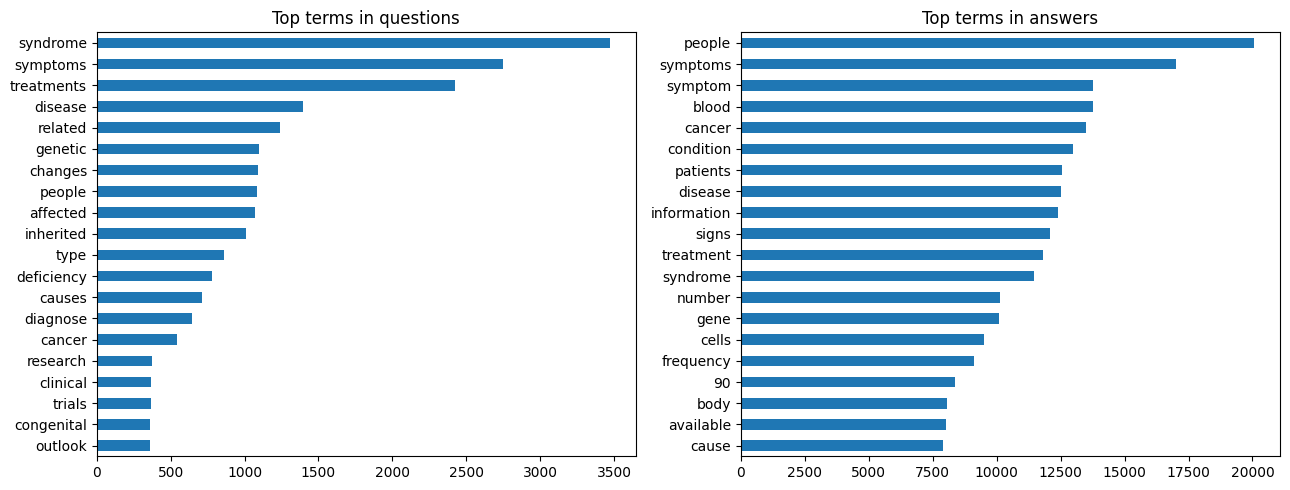

Question vocabulary size: 5080
Answer vocabulary size: 65255


In [10]:
from sklearn.feature_extraction.text import CountVectorizer

def top_terms(texts, n=20):
    cv = CountVectorizer(stop_words="english", max_features=5000)
    counts = cv.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_terms(df["question"]).sort_values().plot(kind="barh", ax=axes[0], title="Top terms in questions")
top_terms(df["answer"]).sort_values().plot(kind="barh", ax=axes[1], title="Top terms in answers")
plt.tight_layout()
plt.savefig(f"{ROOT}/results/plots/top_terms.png", dpi=150, bbox_inches="tight")
plt.show()

print("Question vocabulary size:", len(set(" ".join(df["question"]).lower().split())))
print("Answer vocabulary size:", len(set(" ".join(df["answer"]).lower().split())))

### 7.5 Questions per answer
counts how many questions share each answer.

count    15723.00
mean         1.00
std          0.09
min          1.00
25%          1.00
50%          1.00
75%          1.00
max          5.00
dtype: float64
Answers with more than 1 question: 40


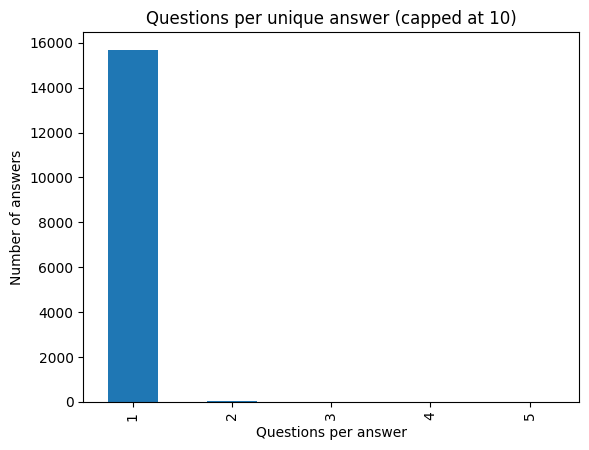

In [11]:
df["answer_id"] = df["answer"].factorize()[0]
group_sizes = df.groupby("answer_id").size()

print(group_sizes.describe().round(2))
print("Answers with more than 1 question:", int((group_sizes > 1).sum()))

group_sizes.clip(upper=10).value_counts().sort_index().plot(kind="bar")
plt.title("Questions per unique answer (capped at 10)")
plt.xlabel("Questions per answer")
plt.ylabel("Number of answers")
plt.savefig(f"{ROOT}/results/plots/questions_per_answer.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.6 Symptom subset
isolates the symptom questions and prints three examples.

In [12]:
symptoms = df[df["qtype"].str.contains("symptom", na=False)]
print("Symptom questions:", len(symptoms), f"({100 * len(symptoms) / len(df):.1f}% of data)")
print("Median answer length (words):", int(symptoms["a_words"].median()))

for _, row in symptoms.sample(3, random_state=1).iterrows():
    print("\nQ:", row["question"])
    print("A:", row["answer"][:300], "...")

Symptom questions: 2746 (17.4% of data)
Median answer length (words): 279

Q: What are the symptoms of Radius absent anogenital anomalies ?
A: What are the signs and symptoms of Radius absent anogenital anomalies? The Human Phenotype Ontology provides the following list of signs and symptoms for Radius absent anogenital anomalies. If the information is available, the table below includes how often the symptom is seen in people with this co ...

Q: What are the symptoms of Spinocerebellar ataxia 40 ?
A: What are the signs and symptoms of Spinocerebellar ataxia 40? The Human Phenotype Ontology provides the following list of signs and symptoms for Spinocerebellar ataxia 40. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can u ...

Q: What are the symptoms of Chondrodysplasia acromesomelic with genital anomalies ?
A: What are the signs and symptoms of Chondrodysplasia acromesomelic with genital anomalies? The Human

### 7.7 Split analysis
checks that train, val and test look alike (sizes, question types, lengths).

In [13]:
splits = {"train": train, "val": val, "test": test}

# Sizes
print({name: len(part) for name, part in splits.items()})

# Question type balance across splits
dist = pd.concat(
    {name: part["qtype"].value_counts(normalize=True) for name, part in splits.items()},
    axis=1,
).fillna(0).round(3)
print("\nQuestion type share per split:\n", dist)

# Length balance across splits
print("\nMedian answer words per split:",
      {name: int(part["answer"].str.split().str.len().median()) for name, part in splits.items()})

# Same question text appearing in train (different answer)
train_q = set(train["question"].str.lower())
for name, part in [("val", val), ("test", test)]:
    share = part["question"].str.lower().isin(train_q).mean()
    print(f"{name}: {100 * share:.1f}% of questions also appear in train (with a different answer)")

{'train': 12624, 'val': 1585, 'test': 1577}

Question type share per split:
                  train    val   test
qtype                               
information      0.282  0.314  0.278
symptoms         0.173  0.175  0.178
treatment        0.155  0.148  0.152
genetic changes  0.071  0.061  0.063
frequency        0.067  0.066  0.075
inheritance      0.063  0.068  0.056
causes           0.046  0.046  0.035
exams and tests  0.041  0.040  0.043
research         0.025  0.021  0.016
outlook          0.022  0.018  0.029
susceptibility   0.020  0.016  0.030
considerations   0.015  0.012  0.016
prevention       0.013  0.009  0.019
stages           0.005  0.004  0.004
complications    0.003  0.003  0.004
support groups   0.000  0.000  0.000

Median answer words per split: {'train': 143, 'val': 144, 'test': 144}
val: 17.5% of questions also appear in train (with a different answer)
test: 18.4% of questions also appear in train (with a different answer)


### 7.8 Sample inspection
**What it does:** prints five random test examples.

In [14]:
for _, row in test.sample(5, random_state=7).iterrows():
    print(f"[{row['qtype']}] Q: {row['question']}")
    print(f"A: {row['answer'][:250]}...\n")

[information] Q: What is (are) enlarged parietal foramina ?
A: Enlarged parietal foramina is an inherited condition of impaired skull development. It is characterized by enlarged openings (foramina) in the parietal bones, which are the two bones that form the top and sides of the skull. This condition is due to ...

[treatment] Q: What are the treatments for Meier-Gorlin syndrome ?
A: These resources address the diagnosis or management of Meier-Gorlin syndrome: - Genetic Testing Registry: Meier-Gorlin syndrome - Genetic Testing Registry: Meier-Gorlin syndrome 2 - Genetic Testing Registry: Meier-Gorlin syndrome 3 - Genetic Testing ...

[genetic changes] Q: What are the genetic changes related to fibrochondrogenesis ?
A: Fibrochondrogenesis can result from mutations in the COL11A1 or COL11A2 gene. These genes provide instructions for making components of type XI collagen, which is a complex molecule that gives structure and strength to the connective tissues that sup...

[information] Q:

## 8. Save the summary
saves the key dataset numbers as a CSV.

In [15]:
summary = {
    "total_pairs": len(df),
    "unique_answers": int(df["answer"].nunique()),
    "unique_questions": int(df["question"].nunique()),
    "question_types": int(df["qtype"].nunique()),
    "median_question_words": int(df["q_words"].median()),
    "median_answer_words": int(df["a_words"].median()),
    "train": len(train), "val": len(val), "test": len(test),
}
pd.Series(summary).to_csv(ROOT / "results/metrics/data_summary.csv", header=["value"])
pd.Series(summary)

total_pairs              15786
unique_answers           15723
unique_questions         14433
question_types              16
median_question_words        8
median_answer_words        143
train                    12624
val                       1585
test                      1577
dtype: int64